# Parte 2 · Clasificación de tumores de mama (Wisconsin)

**Objetivo:** clasificar si un tumor es **maligno** o **benigno** a partir de 30 características calculadas sobre imágenes de una biopsia (aspiración con aguja fina).

**Plan:** exploración breve → división entrenamiento / validación / prueba → entrenar 4 modelos → compararlos **solo en validación** → elegir uno → evaluarlo **una sola vez** en prueba.

> **Detalle importante del dataset:** en `load_breast_cancer`, `target = 0` significa **maligno** y `1` benigno. Como lo que nos interesa detectar es el cáncer, re-etiquetamos para que la **clase positiva (1) sea maligno**. Así *precisión* y *recall* hablan de detectar cáncer, que es lo que importa clínicamente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

SEMILLA = 42
pd.set_option("display.precision", 3)

## 1. Exploración breve

In [2]:
datos = load_breast_cancer(as_frame=True)
X = datos.data
y = (datos.target == 0).astype(int)  # 1 = maligno, 0 = benigno

print(f"Registros: {X.shape[0]}  ·  Variables: {X.shape[1]}  ·  Valores faltantes: {X.isna().sum().sum()}")
print("\nCasos por clase:")
print(y.map({1: "maligno", 0: "benigno"}).value_counts().to_frame("n").assign(proporción=lambda d: d.n / d.n.sum()))

Registros: 569  ·  Variables: 30  ·  Valores faltantes: 0

Casos por clase:
           n  proporción
target                  
benigno  357       0.627
maligno  212       0.373


In [3]:
print("Variables (10 medidas × media, error estándar y peor valor):")
print(list(X.columns))
X.describe().T[["mean", "std", "min", "max"]].head(10)

Variables (10 medidas × media, error estándar y peor valor):
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


Observaciones:
- **569 registros, 30 variables numéricas, sin valores faltantes.**
- Clases **desbalanceadas**: ~63 % benignos y ~37 % malignos. Por eso el *accuracy* solo puede ser engañoso (ver sección 6) y la división se hace **estratificada**.
- Las variables están en **escalas muy distintas** (p. ej. `mean area` en cientos, `mean smoothness` en décimas). Los modelos basados en distancias o en gradiente (regresión logística, SVM, KNN) necesitan **estandarizar**; Random Forest no.
- Hay variables muy correlacionadas (radio, perímetro y área miden casi lo mismo).

## 2. División entrenamiento / validación / prueba

60 % entrenamiento · 20 % validación · 20 % prueba, **estratificada** para conservar la proporción de malignos en los tres conjuntos.

El escalado va **dentro de un `Pipeline`**: el `StandardScaler` aprende media y desviación **solo con entrenamiento**, así no se filtra información de validación ni de prueba (*data leakage*).

In [4]:
X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEMILLA)
X_val, X_prueba, y_val, y_prueba = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEMILLA)

pd.DataFrame({
    "registros": [len(y_ent), len(y_val), len(y_prueba)],
    "% malignos": [y_ent.mean(), y_val.mean(), y_prueba.mean()],
}, index=["entrenamiento", "validación", "prueba"])

,registros,% malignos
entrenamiento,341,0.372
validación,114,0.377
prueba,114,0.368


## 3. Modelos

| Modelo | Cómo funciona | Diferencia clave |
|---|---|---|
| **Regresión logística** | Combina linealmente las variables y pasa el resultado por una sigmoide para obtener una probabilidad. Aprende un peso por variable. | Frontera de decisión **lineal**; interpretable (cada peso dice cuánto empuja hacia maligno). |
| **Random Forest** | Entrena cientos de árboles de decisión, cada uno con una muestra distinta de datos y variables, y vota. | **No lineal**, no necesita escalar, captura interacciones; tiende a memorizar el entrenamiento. |
| **SVM (kernel RBF)** | Busca la frontera que deja el **mayor margen** entre clases, en un espacio transformado por el kernel. | No lineal y robusto en pocas muestras; sensible a la escala y a sus hiperparámetros (C, γ). |
| **KNN (k = 5)** | Clasifica un caso nuevo según la clase mayoritaria de sus 5 vecinos más cercanos. | No "aprende" parámetros: memoriza los datos; depende totalmente de la distancia y la escala. |

In [5]:
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEMILLA)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

def puntaje(modelo, X):
    """Puntaje continuo para el AUC: probabilidad si existe; si no, distancia a la frontera (SVM)."""
    return modelo.predict_proba(X)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X)

for modelo in modelos.values():
    modelo.fit(X_ent, y_ent)

## 4. Comparación en validación

In [6]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"VP": tp, "FN": fn, "FP": fp, "VN": tn,
            "accuracy": accuracy_score(y, pred), "precisión": precision_score(y, pred),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "AUC": roc_auc_score(y, puntaje(modelo, X))}

tabla = pd.DataFrame({n: metricas(m, X_val, y_val) for n, m in modelos.items()}).T
tabla

,VP,FN,FP,VN,accuracy,precisión,recall,F1,AUC
Regresión logística,40.0,3.0,0.0,71.0,0.974,1.000,0.930,0.964,1.000
Random Forest,39.0,4.0,1.0,70.0,0.956,0.975,0.907,0.940,0.995
SVM (RBF),37.0,6.0,0.0,71.0,0.947,1.000,0.860,0.925,0.998
KNN (k=5),38.0,5.0,0.0,71.0,0.956,1.000,0.884,0.938,0.996


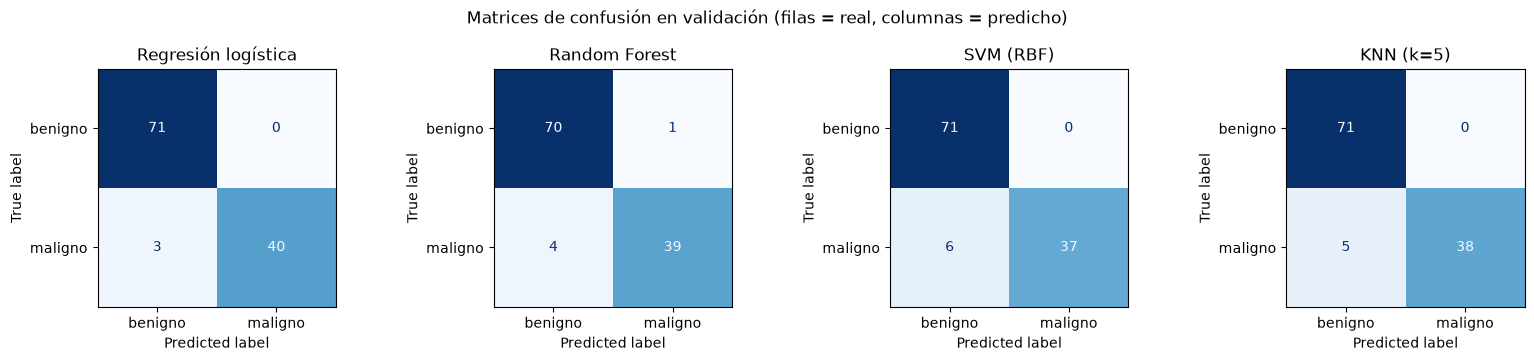

In [7]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.6))
for eje, (nombre, modelo) in zip(ejes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_val, y_val, display_labels=["benigno", "maligno"],
                                          cmap="Blues", colorbar=False, ax=eje)
    eje.set_title(nombre)
plt.suptitle("Matrices de confusión en validación (filas = real, columnas = predicho)")
plt.tight_layout()

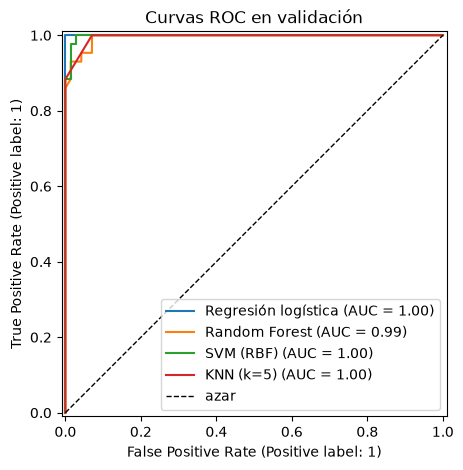

In [8]:
fig, eje = plt.subplots(figsize=(5.5, 5))
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_predictions(y_val, puntaje(modelo, X_val), name=nombre, ax=eje)
eje.plot([0, 1], [0, 1], "k--", lw=1, label="azar")
eje.set_title("Curvas ROC en validación")
eje.legend(loc="lower right");

### ¿Overfitting o underfitting?
Comparamos el desempeño en **entrenamiento** contra **validación**. Una brecha grande indica que el modelo memorizó (overfitting); un desempeño bajo en ambos indicaría que no aprendió el patrón (underfitting).

In [9]:
brecha = pd.DataFrame({
    n: {"accuracy entrenamiento": accuracy_score(y_ent, m.predict(X_ent)),
        "accuracy validación": accuracy_score(y_val, m.predict(X_val))}
    for n, m in modelos.items()
}).T
brecha["brecha"] = brecha["accuracy entrenamiento"] - brecha["accuracy validación"]
brecha

,accuracy entrenamiento,accuracy validación,brecha
Regresión logística,0.991,0.974,0.018
Random Forest,1.000,0.956,0.044
SVM (RBF),0.988,0.947,0.041
KNN (k=5),0.974,0.956,0.017


## 5. Elección del modelo

**Criterio:** en este problema un **falso negativo** (decir "benigno" a un tumor maligno) es mucho más grave que un falso positivo (que solo lleva a más estudios). Por eso priorizamos **recall de la clase maligna**, y después F1 y AUC.

**Elegido: Regresión logística.** En validación tiene el **mayor recall** (0.93, solo 3 malignos no detectados), **cero falsos positivos**, el mejor F1 y un AUC prácticamente perfecto. Además es el modelo más simple e **interpretable**, y su brecha entrenamiento-validación es pequeña.

Random Forest llega a 100 % en entrenamiento, una señal de sobreajuste, y no supera a la regresión logística en validación.

**Ajuste del umbral (con validación, no con prueba):** con el umbral por defecto de 0.5 se escapan 3 malignos. Como el AUC es casi 1, las probabilidades separan muy bien las clases. Podemos **bajar el umbral** para detectar más malignos a cambio de algunos falsos positivos, y lo elegimos mirando **solo validación**.

In [10]:
elegido = modelos["Regresión logística"]
prob_val = elegido.predict_proba(X_val)[:, 1]
umbrales = pd.DataFrame([
    {"umbral": u, "recall": recall_score(y_val, prob_val >= u), "precisión": precision_score(y_val, prob_val >= u),
     "FN": int(((prob_val < u) & (y_val == 1)).sum()), "FP": int(((prob_val >= u) & (y_val == 0)).sum())}
    for u in [0.5, 0.4, 0.3, 0.2, 0.1]
])
umbrales

,umbral,recall,precisión,FN,FP
0,0.5,0.930,1.000,3,0
1,0.4,0.953,1.000,2,0
2,0.3,0.977,1.000,1,0
3,0.2,1.000,0.977,0,1
4,0.1,1.000,0.956,0,2


In [11]:
# El umbral más alto que no deja escapar ningún maligno en validación (si no existe, se queda en 0.5)
sin_fn = umbrales[umbrales.FN == 0]
UMBRAL = float(sin_fn.umbral.max()) if len(sin_fn) else 0.5
print(f"Umbral elegido con validación: {UMBRAL}")

Umbral elegido con validación: 0.2


## 6. Evaluación final en prueba (una sola vez)

Hasta aquí **no se ha mirado el conjunto de prueba**. Ahora se evalúa una sola vez el modelo elegido con el umbral fijado en validación. Este número estima cómo se comportaría con pacientes nuevos.

In [12]:
prob_prueba = elegido.predict_proba(X_prueba)[:, 1]
final = {}
for nombre, u in [("umbral 0.5", 0.5), (f"umbral {UMBRAL} (elegido)", UMBRAL)]:
    pred = (prob_prueba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_prueba, pred).ravel()
    final[nombre] = {"VP": tp, "FN": fn, "FP": fp, "VN": tn, "accuracy": accuracy_score(y_prueba, pred),
                     "precisión": precision_score(y_prueba, pred), "recall": recall_score(y_prueba, pred),
                     "F1": f1_score(y_prueba, pred), "AUC": roc_auc_score(y_prueba, prob_prueba)}
pd.DataFrame(final).T

,VP,FN,FP,VN,accuracy,precisión,recall,F1,AUC
umbral 0.5,38.0,4.0,0.0,72.0,0.965,1.000,0.905,0.950,0.994
umbral 0.2 (elegido),41.0,1.0,3.0,69.0,0.965,0.932,0.976,0.953,0.994


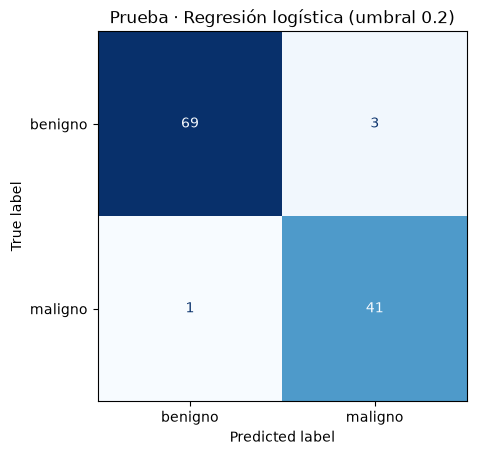

In [13]:
ConfusionMatrixDisplay.from_predictions(y_prueba, (prob_prueba >= UMBRAL).astype(int),
                                        display_labels=["benigno", "maligno"], cmap="Blues", colorbar=False)
plt.title(f"Prueba · Regresión logística (umbral {UMBRAL})");

**Resultado en prueba.**
- Con el umbral por defecto (0.5) el modelo deja escapar **4 de 42 malignos** (recall 0.905).
- Con el umbral 0.2, elegido en validación, solo se escapa **1** (recall 0.976), a cambio de 3 falsos positivos.
- El **accuracy es idéntico (0.965) en ambos casos**, aunque clínicamente el segundo es mucho mejor. Es un ejemplo directo de por qué el accuracy no basta.
- El AUC en prueba (0.994) es muy cercano al de validación, así que el modelo **generaliza** y no hay señales de sobreajuste a validación.

## 7. Preguntas

**¿Cómo funciona cada modelo y en qué se diferencian?**
Ver la tabla de la sección 3. En resumen:
- La **regresión logística** traza una frontera **lineal** y da probabilidades calibradas e interpretables.
- **Random Forest** promedia muchos árboles. Es **no lineal** y no necesita escalar, pero puede memorizar.
- **SVM** maximiza el margen entre clases y, con el kernel RBF, encuentra fronteras curvas.
- **KNN** no entrena: decide por cercanía a los ejemplos conocidos.

**¿Para qué sirven entrenamiento, validación y prueba? ¿Por qué prueba solo al final?**
- **Entrenamiento:** el modelo aprende sus parámetros.
- **Validación:** se comparan modelos y se toman decisiones (qué modelo, qué umbral, qué hiperparámetros).
- **Prueba:** se estima el desempeño con datos **nunca vistos**.

Si usáramos prueba para decidir, esas decisiones se ajustarían a ese conjunto en particular y el resultado sería **optimista**: ya no mediría la generalización. Por eso se usa una sola vez, al final.

**¿Qué es overfitting y underfitting? ¿Hubo señales?**
- **Overfitting:** el modelo memoriza ruido del entrenamiento. Le va muy bien ahí y peor con datos nuevos (brecha grande).
- **Underfitting:** el modelo es demasiado simple y le va mal en ambos.

En la tabla de brechas, **Random Forest** llega a 100 % en entrenamiento y cae 4.4 puntos en validación, y el **SVM** cae 4.1 puntos. Son **sobreajustes leves**: en Random Forest es típico de árboles sin límite de profundidad, y en el SVM se podría corregir ajustando C y γ. La regresión logística y KNN tienen brechas de menos de 2 puntos. Ningún modelo muestra underfitting: todos superan el 94 % en validación.

**¿Diferencia entre precisión y recall? ¿Cuál importa más aquí?**
- **Precisión** = VP / (VP + FP): de los que el modelo marcó como malignos, cuántos lo eran.
- **Recall** = VP / (VP + FN): de los malignos reales, cuántos detectó.

Aquí importa más el **recall**. Un falso negativo deja un cáncer sin tratar; un falso positivo implica una prueba adicional. Por eso bajamos el umbral, aceptando algunos falsos positivos más.

**¿Por qué no basta el accuracy?**
Con 63 % de benignos, un modelo que siempre dijera "benigno" tendría 63 % de accuracy sin detectar un solo cáncer. El accuracy mezcla los dos tipos de error como si costaran lo mismo y esconde **cuál** error se comete. En diagnóstico médico no cuestan lo mismo.

**Matriz de confusión, métricas y AUC**
- La **matriz de confusión** cuenta los cuatro casos: verdaderos positivos (maligno detectado), falsos negativos (maligno no detectado), falsos positivos (benigno marcado como maligno) y verdaderos negativos.
- De ella salen todas las métricas:
  - **accuracy** = aciertos / total
  - **precisión** y **recall** (arriba)
  - **F1** = media armónica de precisión y recall; solo es alta si ambas lo son.
- El **AUC** es el área bajo la curva ROC, que grafica recall contra tasa de falsos positivos para **todos los umbrales**. Equivale a la probabilidad de que el modelo le dé mayor puntaje a un maligno al azar que a un benigno al azar. 0.5 es azar y 1.0 es separación perfecta. Es útil porque **no depende del umbral**: mide qué tan bien ordena el modelo, y después se elige el umbral según el costo de cada error.